# 04 · Pronóstico de volatilidad: EWMA y GARCH contra XGBoost

**Bloque 4.** Objetivo: pronosticar la volatilidad del día siguiente de un portafolio y comprobar, fuera de muestra,
si un modelo de *machine learning* (XGBoost) mejora a los modelos clásicos de series de tiempo (EWMA y GARCH).

La volatilidad es el insumo del VaR del notebook 03: un mejor pronóstico de volatilidad es un mejor modelo de riesgo.
La hipótesis de partida es modesta: los modelos clásicos son difíciles de superar con datos diarios, y si XGBoost no les gana
se reporta así.

In [1]:
import sys
from pathlib import Path

# Permite importar `src` al ejecutar desde la carpeta notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data, plots, risk, volatility

plots.set_style()
TD = config.TRADING_DAYS

## 1. Serie a pronosticar

El portafolio igual ponderado de las 31 emisoras con rebalanceo diario (el promedio de sus retornos de cada día).
Se usa toda la historia disponible, porque los modelos necesitan muchos datos para entrenar.

In [2]:
prices = data.clean_prices(data.download_prices())
stock_rets, _ = data.split_benchmark(data.compute_returns(prices, log=False))

# Días en que ninguna emisora cambió de precio: Yahoo Finance los publica con precios repetidos.
# Un retorno exactamente cero no es un dato de mercado y rompe la evaluación (QLIKE usa el logaritmo).
flat = (stock_rets == 0).all(axis=1)
print("Días sin movimiento en las 31 emisoras (se quitan):", [str(d.date()) for d in stock_rets.index[flat]])
stock_rets = stock_rets[~flat]

r = stock_rets.mean(axis=1).rename("Igual ponderado")
print(f"Retornos diarios: {len(r)} | {r.index.min().date()} → {r.index.max().date()}")
print(f"Volatilidad anual de toda la muestra: {r.std() * np.sqrt(TD):.1%}")

Días sin movimiento en las 31 emisoras (se quitan): ['2017-01-02', '2019-12-31', '2020-10-09', '2020-10-19']
Retornos diarios: 2820 | 2015-07-20 → 2026-10-08
Volatilidad anual de toda la muestra: 15.4%


## 2. Qué se pronostica y cómo se evalúa

**Objetivo.** La varianza del día siguiente. La varianza verdadera de un día no se observa, así que se usa como referencia el
retorno al cuadrado de ese día: es una medida muy ruidosa, pero en promedio acierta.

**Métricas** (menor es mejor):

- **QLIKE:** `r²/f − log(r²/f) − 1`, donde `f` es la varianza pronosticada. Es la medida estándar porque sigue ordenando bien
  los modelos aunque la referencia sea ruidosa, y castiga más subestimar el riesgo que sobreestimarlo.
- **MSE:** error cuadrático medio de la varianza. Fácil de entender, pero lo dominan unos pocos días extremos.

**Validación walk-forward.** Los primeros 1,000 días (unos cuatro años) solo sirven para entrenar. A partir de ahí,
cada 21 días se reestima cada modelo con todos los datos disponibles hasta ese momento (ventana expansiva) y se pronostican
los 21 días siguientes, uno por uno, usando cada día la información del día anterior. Nunca se entrena con datos posteriores
al día que se pronostica, y no hay particiones aleatorias.

| Modelo | Qué es | Qué se estima |
|---|---|---|
| Ventana fija | Volatilidad de los últimos 252 días | Nada |
| EWMA | Promedio de retornos al cuadrado que pesa más lo reciente (λ = 0.94) | Nada |
| GARCH(1,1) | Como EWMA, pero estima cuánto pesa lo reciente y hacia qué nivel regresa la volatilidad | 4 parámetros |
| XGBoost | Árboles de decisión sobre 13 variables: retornos al cuadrado recientes, promedios a 5, 21 y 63 días, EWMA, caídas, y la varianza y dispersión de las emisoras | 200 árboles |

Los hiperparámetros de XGBoost y los parámetros del esquema (1,000 días, 21 días, λ = 0.94) se fijaron de antemano; no se hizo búsqueda.

In [3]:
MIN_TRAIN, REFIT_EVERY = 1000, 21

features = volatility.make_features(r, stock_rets)
xgb_forecast, importance = volatility.xgboost_forecast(r, features, min_train=MIN_TRAIN, refit_every=REFIT_EVERY)

forecasts = pd.DataFrame({
    "Ventana fija": volatility.rolling_forecast(r, 252),
    "EWMA": volatility.ewma_forecast(r),
    "GARCH": volatility.garch_forecast(r, min_train=MIN_TRAIN, refit_every=REFIT_EVERY),
    "XGBoost": xgb_forecast,
}).dropna()  # mismo periodo de prueba para todos

realized_var = (r**2).loc[forecasts.index]
print(f"Periodo de prueba: {forecasts.index.min().date()} → {forecasts.index.max().date()} ({len(forecasts)} días)")
print(f"Variables de XGBoost: {features.shape[1]} | reentrenamientos: {len(range(MIN_TRAIN, len(r), REFIT_EVERY))}")

Periodo de prueba: 2019-07-12 → 2026-10-08 (1820 días)
Variables de XGBoost: 13 | reentrenamientos: 87


## 3. Resultados fuera de muestra

Las columnas "vs EWMA" comparan cada modelo contra EWMA, la referencia más simple que ya reacciona a la volatilidad reciente.
El estadístico *t* (prueba de Diebold-Mariano) dice si esa diferencia es distinguible del azar: negativo significa que el modelo
es mejor que EWMA, y se pide |t| > 2.

In [4]:
qlike_losses = pd.DataFrame({m: volatility.qlike_losses(realized_var, forecasts[m] ** 2) for m in forecasts})
mse_losses = pd.DataFrame({m: volatility.mse_losses(realized_var, forecasts[m] ** 2) for m in forecasts})

def versus(losses: pd.DataFrame, base: str = "EWMA") -> pd.Series:
    return pd.Series({m: volatility.loss_difference_tstat(losses[m], losses[base]) if m != base else np.nan for m in losses})

results = pd.DataFrame({
    "QLIKE": qlike_losses.mean(),
    "QLIKE vs EWMA": qlike_losses.mean() / qlike_losses["EWMA"].mean() - 1,
    "t (QLIKE)": versus(qlike_losses),
    "MSE (×1e-8)": mse_losses.mean() * 1e8,
    "MSE vs EWMA": mse_losses.mean() / mse_losses["EWMA"].mean() - 1,
    "t (MSE)": versus(mse_losses),
    "Volatilidad anual pronosticada": np.sqrt((forecasts**2).mean() * TD),
})
print(f"Volatilidad anual realizada en el periodo de prueba: {np.sqrt(realized_var.mean() * TD):.1%}")
results.sort_values("QLIKE").style.format({
    "QLIKE": "{:.3f}", "QLIKE vs EWMA": "{:+.1%}", "t (QLIKE)": "{:.2f}", "MSE (×1e-8)": "{:.2f}",
    "MSE vs EWMA": "{:+.1%}", "t (MSE)": "{:.2f}", "Volatilidad anual pronosticada": "{:.1%}",
}, na_rep="–")

Volatilidad anual realizada en el periodo de prueba: 16.8%


,QLIKE,QLIKE vs EWMA,t (QLIKE),MSE (×1e-8),MSE vs EWMA,t (MSE),Volatilidad anual pronosticada
GARCH,1.396,-1.1%,-1.42,6.69,-8.0%,-2.39,16.2%
EWMA,1.411,+0.0%,–,7.27,+0.0%,–,16.8%
XGBoost,1.534,+8.7%,4.49,7.58,+4.2%,1.13,14.4%
Ventana fija,1.555,+10.2%,4.02,8.50,+16.9%,2.31,16.8%


**Comentarios:**
- **Mejor modelo:** El mejor modelo parece ser GARCH; pronostica mejor que el resto tanto en QLIKE como en MSE. Hay que tomar en cuenta que en QLIKE la diferencia con EWMA tiene un t menor a 2 (−1.42), por lo que aparenta ser mejor que EWMA, pero no es una certeza y podría ser ruido. En MSE la diferencia sí es distinguible (t = −2.39), aunque esa métrica la dominan unos pocos días extremos, por lo que la conclusión se apoya en QLIKE.
- **XGBoost:** Se queda considerablemente detrás de EWMA y GARCH en QLIKE; en MSE también es peor que EWMA, pero esa diferencia no es distinguible (t = 1.13). Queda en tercer lugar de cuatro. El principal motivo por el que fue tan malo en QLIKE es que subestimó la volatilidad (pronosticó 14.4% anual en promedio contra 16.8% realizada) y QLIKE castiga especialmente eso.
- **Ventana fija:** Es el peor modelo en las dos métricas, y de forma distinguible frente a EWMA (t de 4.02 en QLIKE).

## 4. Cómo se comporta cada pronóstico

La línea gris es la volatilidad que efectivamente se realizó en los 21 días siguientes a cada fecha. Mira hacia adelante,
así que ningún modelo la conoce: sirve como referencia de qué tan cerca quedó cada pronóstico.

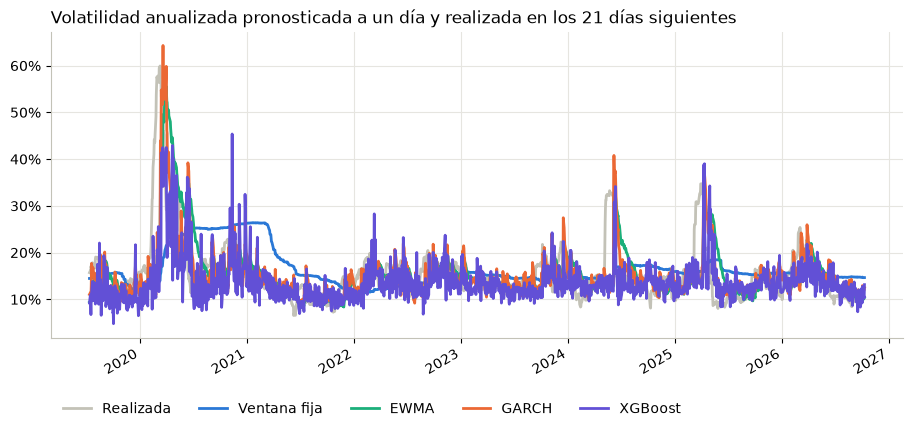

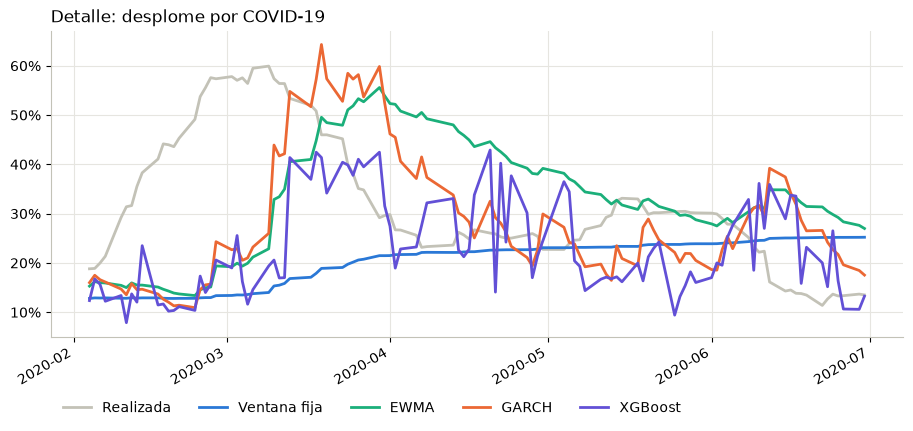

Pronóstico más alto de cada modelo (volatilidad anualizada):
Ventana fija    26%
EWMA            56%
GARCH           64%
XGBoost         45%


In [5]:
annual = forecasts * np.sqrt(TD)
annual["Realizada"] = (r.rolling(21).std().shift(-20) * np.sqrt(TD)).loc[annual.index]
order = ["Realizada", "Ventana fija", "EWMA", "GARCH", "XGBoost"]

ax = plots.line_chart(annual[order], "Volatilidad anualizada pronosticada a un día y realizada en los 21 días siguientes")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.show()

ax = plots.line_chart(annual.loc["2020-02-03":"2020-06-30", order], "Detalle: desplome por COVID-19")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.show()

print("Pronóstico más alto de cada modelo (volatilidad anualizada):")
print(annual[forecasts.columns].max().map("{:.0%}".format).to_string())

**Comentarios:**
- **Ventana fija:** No reacciona al desplome por COVID-19; sube muy poco y a destiempo.
- **EWMA:** Sí reacciona al desplome, pero no de forma tan ágil; tiene cierto retraso respecto a la realidad.
- **GARCH:** Es el que mejor reacciona y en menor tiempo, y vuelve con rapidez a la volatilidad "normal" del portafolio, porque el modelo tiende a regresar a su nivel de largo plazo.
- **XGBoost:** Sí reacciona, pero se topa: en el desplome llega a 43% y su máximo en todo el periodo es 45%, contra 64% de GARCH; además salta mucho de un día a otro. Está limitado por los datos con los que fue entrenado, que no incluían una situación tan extrema de volatilidad: un modelo de árboles no puede pronosticar más allá de lo que vio.

## 5. ¿El resultado depende del periodo?

QLIKE promedio por año. Si un modelo solo gana o pierde por un año extremo, aquí se ve.

In [6]:
by_year = qlike_losses.groupby(qlike_losses.index.year).mean()
by_year["Mejor"] = by_year.idxmin(axis=1)
display(by_year.style.format({m: "{:.2f}" for m in forecasts}).set_caption("QLIKE por año (2019 y 2026 son años parciales)"))
print("Años en que cada modelo fue el mejor:")
print(by_year["Mejor"].value_counts().to_string())

,Ventana fija,EWMA,GARCH,XGBoost,Mejor
Date,,,,,
2019,1.19,1.25,1.23,1.66,Ventana fija
2020,2.20,1.44,1.39,1.79,GARCH
2021,1.50,1.29,1.29,1.36,EWMA
2022,1.41,1.35,1.36,1.45,EWMA
2023,1.38,1.40,1.44,1.39,Ventana fija
2024,1.65,1.68,1.64,1.76,GARCH
2025,1.50,1.43,1.36,1.50,GARCH
2026,1.39,1.35,1.35,1.41,GARCH


Años en que cada modelo fue el mejor:
Mejor
GARCH           4
Ventana fija    2
EWMA            2


**Comentarios:**
- **GARCH:** Resulta ser el mejor a través de los años, siendo el mejor modelo en la mitad de la muestra (4 de 8 años). Pero también hay que mencionar que en algunos años en los que gana es por una diferencia casi imperceptible.
- **EWMA y ventana fija:** Son el mejor modelo en 2 años cada uno. Son diferencias muy cerradas, pero tienen la ventaja al menos en un par de ocasiones. La ventana fija falla sobre todo en 2020 (2.20, el peor resultado de toda la tabla), cuando la volatilidad cambió de golpe.
- **XGBoost:** Nunca es el mejor y es el peor en 4 de los 8 años (2019, 2022, 2024 y 2026). Solo en 2020 y 2021 la ventana fija queda claramente por debajo de él. Esto probablemente se debe a la tendencia a subestimar el riesgo y a que QLIKE castiga más ese error.

## 6. Qué variables usa XGBoost

Importancia promedio de cada variable en todos los reentrenamientos (qué tanto reduce el error cuando el modelo la usa).
Indica qué información aprovecha el modelo, no una relación causal.

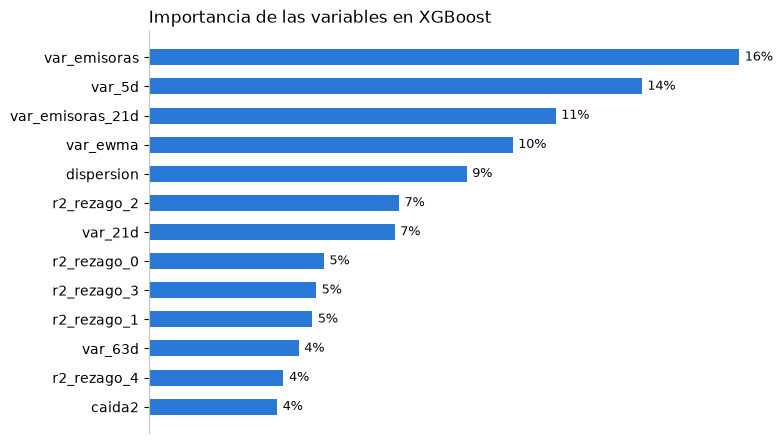

In [7]:
plots.barh_chart(importance, "Importancia de las variables en XGBoost")
plt.show()

**Comentarios:**
- **Variables más importantes:** Le da mayor peso a la información de las emisoras individuales, con variables como var_emisoras, var_emisoras_21d o dispersion. También le da bastante peso a los promedios de los últimos días, como var_5d o var_ewma.
- **XGBoost vs EWMA y GARCH:** La información de las emisoras individuales no es usada por EWMA ni por GARCH, mientras que la información de los últimos días sí es justamente lo que usan EWMA y GARCH. Aun con esa información adicional, XGBoost pronosticó peor.

## 7. Consecuencia práctica: el VaR con cada pronóstico

Se convierte cada pronóstico de volatilidad en un VaR al 99% multiplicándolo por 2.33 (el cuantil de la normal), como en el
método EWMA del notebook 03, y se cuentan las excepciones. El periodo y la serie son distintos a los del notebook 03,
así que los números no son comparables entre notebooks; lo que importa es la comparación entre modelos.

In [8]:
from scipy import stats

z99 = -stats.norm.ppf(0.01)
var_rows = {}
for model in forecasts:
    out = risk.backtest_var(r, z99 * forecasts[model], alpha=0.99)
    hits = -r.loc[forecasts.index] > z99 * forecasts[model]
    var_rows[model] = {
        "Excepciones": out["Excepciones"],
        "Esperadas": out["Esperadas"],
        "p-value (Kupiec)": out["p-value"],
        "Excepciones 20-feb a 30-abr de 2020": int(hits.loc["2020-02-20":"2020-04-30"].sum()),
    }
pd.DataFrame(var_rows).T.style.format({"Excepciones": "{:.0f}", "Esperadas": "{:.1f}", "p-value (Kupiec)": "{:.3f}",
                                       "Excepciones 20-feb a 30-abr de 2020": "{:.0f}"})

,Excepciones,Esperadas,p-value (Kupiec),Excepciones 20-feb a 30-abr de 2020
Ventana fija,27,18.2,0.053,10
EWMA,29,18.2,0.019,3
GARCH,31,18.2,0.006,3
XGBoost,47,18.2,0.000,7


**Comentarios:**
- **Ventana fija:** Muestra la menor cantidad de excepciones y el mejor resultado en la prueba de Kupiec, pero tiene demasiadas excepciones en el periodo de crisis de la pandemia (10); eso reduce mucho la calidad del modelo.
- **EWMA y GARCH:** Presentan resultados muy similares; su principal punto a favor es que "solo" registraron 3 excepciones en el periodo de crisis por el COVID-19. Aun así, la prueba de Kupiec los rechaza a los dos (29 y 31 excepciones contra 18 esperadas): con una buena volatilidad pero con el multiplicador de la normal, el VaR se sigue quedando corto, igual que en el notebook 03.
- **XGBoost:** Es el modelo con mayor cantidad de excepciones (47), pues es el que más subestimó el riesgo y la volatilidad real. Además, cuenta con casi tantas excepciones como la ventana fija en el periodo de crisis (7). Es el peor de los métodos.

## 8. Advertencias metodológicas

- **XGBoost sin búsqueda de hiperparámetros.** Se usó una configuración razonable y fija. Una búsqueda con validación
  walk-forward anidada podría mejorarlo; no se hizo, así que el resultado dice que *esta* configuración no supera a los modelos
  clásicos, no que ningún modelo de ML pueda hacerlo.
- **Una variante probada y no incluida.** Se probó además que XGBoost pronosticara la razón entre la varianza del día siguiente
  y el EWMA, en lugar del nivel. Su QLIKE fue prácticamente igual (1.537 contra 1.534), por lo que no se reporta aparte.
- **Referencia ruidosa.** El retorno al cuadrado de un día es una medida muy imprecisa de la varianza. Con datos intradía se
  podría construir una volatilidad realizada mucho mejor, y ahí es donde los modelos de ML suelen aportar más.
- **MSE dominado por extremos.** Unos pocos días de marzo de 2020 determinan casi todo el MSE; por eso la conclusión se apoya en QLIKE.
- **Una sola serie y un solo horizonte.** Se pronostica un portafolio a un día. No se probó en emisoras individuales ni a horizontes más largos.
- **Datos.** Se quitaron cuatro días en que Yahoo Finance repite los precios de todas las emisoras. Esos días siguen en los
  notebooks 01 a 03, donde su efecto es mínimo (4 de 2,824 días).

## 9. Conclusiones del Bloque 4

- ¿Qué modelo usarías para pronosticar la volatilidad de este portafolio y por qué?  
Utilizaría GARCH o, en su defecto, EWMA. Ambos obtuvieron resultados muy similares en todas las pruebas y fueron los más satisfactorios. XGBoost no cumplió: quedó por detrás de los dos.
- ¿XGBoost mejoró a los modelos clásicos? ¿Cuál es su principal debilidad?  
No solo no mejoró a los modelos clásicos, sino que se quedó muy por detrás de ellos. Considero que su principal debilidad fue el rango de datos con que se entrenó: el entrenamiento no preparó al modelo para la situación extrema de marzo de 2020, y un modelo de árboles no pronostica más allá de lo que vio. Pero el problema no es solo de la crisis: también fue el peor en años tranquilos y subestimó el riesgo de forma sistemática (14.4% contra 16.8% realizada), algo que QLIKE castigó mucho.
- ¿Por qué GARCH y EWMA son tan difíciles de superar con datos diarios?  
Porque GARCH y EWMA están diseñados particularmente para resolver esta problemática solo con datos diarios; es su punto fuerte. La señal que importa es simple (la volatilidad de mañana se parece a la reciente) y ellos la capturan con 4 parámetros o menos, mientras que el objetivo es tan ruidoso que un modelo flexible termina aprendiendo ruido. De hecho, entre las variables que más usa XGBoost están esos mismos promedios recientes. Por eso un modelo de ML tiene desventaja en esta circunstancia.
- ¿Qué harías distinto para darle una oportunidad justa a un modelo de ML?  
Mis ideas principales para darle una oportunidad justa a un modelo de ML como XGBoost serían incluir información intradía o tomar una muestra mucho mayor de datos. Considero que ese es el punto de ventaja que podría tener un modelo de ML respecto a los clásicos. También faltó buscar sus hiperparámetros con validación walk-forward, que aquí se dejaron fijos.
- ¿Qué relación tiene este resultado con el VaR del notebook 03?  
Ambos notebooks buscan resolver el problema que presenta definir correctamente el Value at Risk. En este caso, desde la volatilidad, pues se prueban distintos modelos para medirla de la mejor forma posible. La sección 7 muestra que una buena volatilidad no basta: con EWMA y GARCH el VaR normal sigue siendo rechazado, así que también hace falta el multiplicador correcto. Hipotéticamente, combinar ambos resultados debería mejorar el VaR, usando GARCH con el multiplicador obtenido del histórico filtrado. No se probó en este notebook y, como GARCH apenas mejora a EWMA, la mejora esperada es modesta.